# Phase 8 — The objective function

**Two questions, one of which the project needs answered.**

**The open confound.** Phase 6 found the two-tower beating the FM by 43% (0.1653 vs 0.1159)
and showed only ~10% of that gap is explained by the tower seeing more negatives. Two
candidates remained: the **softmax objective** (a ranking loss over many candidates at once)
and the **tower nonlinearity** (an MLP inside each side). This phase isolates the first by
putting a sampled-softmax loss on the FM backbone — same features, same model class, only the
loss changes. If the FM closes most of the gap, the project's headline result is about the
objective rather than the architecture.

**The framing question.** Rating regression, thresholded classification and pairwise ranking
are routinely described as three losses for one task. They are not. They **train on different
data** and **admit different metrics**, and running them on one backbone makes that concrete.

All four objectives share the gradient path. Each reduces to an error term multiplying the
same `∂ŷ/∂θ`:

| Objective | error term | shape |
|---|---|---|
| `logistic` | `σ(ŷ) − y` | pointwise, absolute target |
| `regression` | `ŷ − rating` | pointwise, absolute target |
| `softmax` | `p − onehot` over 1 positive + N negatives | listwise |
| `bpr` | `p − onehot`, N = 1 | pairwise |

The last line is worth pausing on: **BPR is the softmax with one negative.** They are the same
code path, and that identity falls out of the algebra rather than being imposed.

In [1]:
import sys, time, os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns, joblib
from scipy import stats
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

import data as D, metrics as M
from models.base import rank_users
from models.fm import FactorizationMachine

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
                     "figure.facecolor": "white"})
ACCENT, MUTED, WARN, GOOD, PURPLE = "#2B6CB0", "#A0AEC0", "#C05621", "#2F855A", "#6B46C1"
def pct(x, d=1): return f"{100*x:.{d}f}%"

ds = D.build()
TRAIN, VAL = ds.split_rows("train"), ds.split_rows("val")
K = 10
IH = tuple(D.MF_BLOCKS) + ("history",)
USERS = ds.eval_users(True, target="test")
TRUTH = {int(u): ds.ground_truth(int(u)) for u in USERS}
REACH = {int(u): ds.reachable_truth(int(u), True) for u in USERS}
os.makedirs("cache", exist_ok=True)

FM_LOGISTIC, TOWER = 0.1159, 0.1653      # Phase 4 best FM, Phase 6 best tower
TEST_OBS = ds.split_rows("test")          # observed test ratings, for the RMSE column

def run_obj(objective, seed=42, n_neg=8, tag=None, **kw):
    tag = tag or f"{objective}_n{n_neg}"
    path = f"cache/p8_{tag}_s{seed}.joblib"
    if os.path.exists(path): return joblib.load(path)
    m = FactorizationMachine(k=64, blocks=IH, order=2, lr=0.02, reg_w=1e-5, reg_v=1e-5,
                             epochs=30, batch_size=4096, patience=3, objective=objective,
                             n_neg=n_neg, neg_policy="unobserved_only", neg_ratio=1,
                             seed=seed, verbose=False, **kw)
    t0 = time.time(); m.fit(ds, TRAIN, VAL); fit_s = time.time() - t0
    r, _ = rank_users(m, ds, users=USERS, filtered=True, k=K, progress_every=0, target="test")
    res = M.evaluate_ranking(r, TRUTH, ds.n_items, ds.item_train_count, K, REACH)
    # Attempt an RMSE against the true 1-5 ratings for every objective, whether or not
    # it is meaningful -- the point of the study is which ones can answer at all.
    pred = m.score_rows(ds, TEST_OBS)
    res["rmse_vs_rating"] = float(np.sqrt(np.mean((pred - TEST_OBS["rating"].to_numpy()) ** 2)))
    res["pred_min"], res["pred_max"] = float(pred.min()), float(pred.max())
    res.update(objective=objective, n_neg=n_neg, tag=tag, seed=seed, fit_s=fit_s,
               calibrated=m.calibrated, name=m.name, epochs=len(m.history_))
    joblib.dump(res, path); return res

print(f"\n  reference: FM/logistic {FM_LOGISTIC:.4f}   two-tower {TOWER:.4f}")

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg 9cf199d378
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519



  reference: FM/logistic 0.1159   two-tower 0.1653


---
## 1. Four objectives, one backbone

Three seeds each. Everything but the loss is held fixed: `k=64`, the `ids + history` feature
set, the same optimiser, the same early-stopping rule.

In [2]:
SEEDS = [42, 43, 44]
ARMS = [("logistic", 8), ("regression", 8), ("bpr", 1), ("softmax", 8)]
rows = [run_obj(o, seed=s, n_neg=n) for o, n in ARMS for s in SEEDS]
R8 = pd.DataFrame(rows)
R8.to_csv("results_phase8.csv", index=False)

A8 = (R8.groupby("objective")
        .agg(n=("seed", "size"), ndcg=(f"ndcg@{K}", "mean"),
             se=(f"ndcg@{K}", lambda v: v.std(ddof=1)/np.sqrt(len(v))),
             recall=(f"recall@{K}", "mean"), cov=("coverage", "mean"),
             gini=("gini", "mean"), rmse=("rmse_vs_rating", "mean"),
             lo=("pred_min", "mean"), hi=("pred_max", "mean"),
             fit=("fit_s", "mean"), cal=("calibrated", "first"))
        .reindex(["regression", "logistic", "bpr", "softmax"]))

print(f"  {'objective':<12}{'NDCG@10':>10}{'+-se':>8}{'recall':>9}{'cov':>8}{'gini':>7}"
      f"{'fit s':>8}{'output range':>22}")
print("  " + "-"*84)
for o, r in A8.iterrows():
    print(f"  {o:<12}{r['ndcg']:>10.4f}{r['se']:>8.4f}{r['recall']:>9.4f}{r['cov']:>8.3f}"
          f"{r['gini']:>7.3f}{r['fit']:>8.0f}    [{r['lo']:>8.2f}, {r['hi']:>7.2f}]")
print("  " + "-"*84)
print(f"  {'FM logistic (Phase 4)':<12}{FM_LOGISTIC:>22.4f}")
print(f"  {'two-tower (Phase 6)':<12}{TOWER:>22.4f}")

gap0 = TOWER - A8.loc["logistic", "ndcg"]
print("\n  THE CONFOUND -- tower minus FM, by the FM's objective")
for o in ("logistic", "softmax", "bpr"):
    g = TOWER - A8.loc[o, "ndcg"]
    print(f"    {o:<10} gap {g:+.4f}   share of the logistic-FM gap closed: {pct(1 - g/gap0)}")
t, p = stats.ttest_ind(R8[R8.objective == "softmax"][f"ndcg@{K}"],
                       R8[R8.objective == "logistic"][f"ndcg@{K}"])
print(f"\n  softmax vs logistic on the FM: t = {t:.2f}, p = {p:.3f}")

  objective      NDCG@10    +-se   recall     cov   gini   fit s          output range
  ------------------------------------------------------------------------------------
  regression      0.0524  0.0015   0.0340   0.206  0.969      18    [    0.25,    6.54]
  logistic        0.1159  0.0015   0.0895   0.204  0.956      40    [    0.00,    1.00]
  bpr             0.1078  0.0008   0.0853   0.188  0.960      87    [   -0.54,   41.22]
  softmax         0.1143  0.0001   0.0900   0.179  0.958     162    [   -1.22,   40.14]
  ------------------------------------------------------------------------------------
  FM logistic (Phase 4)                0.1159
  two-tower (Phase 6)                0.1653

  THE CONFOUND -- tower minus FM, by the FM's objective
    logistic   gap +0.0494   share of the logistic-FM gap closed: 0.0%
    softmax    gap +0.0510   share of the logistic-FM gap closed: -3.3%
    bpr        gap +0.0575   share of the logistic-FM gap closed: -16.3%

  softmax vs logistic o

**Changing the loss closes none of the gap.** Softmax (0.1143) and logistic (0.1159) are
statistically indistinguishable on the FM backbone, and BPR sits slightly below both. The
two-tower's 0.1653 is untouched by any of them.

One check is owed before concluding. The FM softmax used 8 negatives; the tower used 256. If a
listwise loss simply needs a larger candidate set, that comparison is unfair — so the range is
pushed to 32.

In [3]:
sweep = [run_obj("softmax", seed=42, n_neg=n) for n in (1, 4, 8, 16, 32)]
SW = pd.DataFrame(sweep)
print(f"  {'negatives':>10}{'rows':>12}{'NDCG@10':>10}{'recall':>9}{'cov':>8}{'fit s':>8}")
print("  " + "-"*57)
n_pos = int((TRAIN.label == 1).sum())
for _, r in SW.iterrows():
    print(f"  {int(r['n_neg']):>10}{n_pos*(int(r['n_neg'])+1)/1e6:>11.2f}M"
          f"{r[f'ndcg@{K}']:>10.4f}{r[f'recall@{K}']:>9.4f}{r['coverage']:>8.3f}{r['fit_s']:>8.0f}")
print(f"\n  spread across a 32x range of negatives: "
      f"{SW[f'ndcg@{K}'].max() - SW[f'ndcg@{K}'].min():.4f}")
print(f"  best softmax {SW[f'ndcg@{K}'].max():.4f}  vs logistic {FM_LOGISTIC:.4f}  "
      f"vs tower {TOWER:.4f}")
peak = SW.loc[SW[f"ndcg@{K}"].idxmax()]
print(f"\n  peak at {int(peak['n_neg'])} negatives ({peak[f'ndcg@{K}']:.4f}); beyond it NDCG falls and")
print(f"  coverage collapses {SW['coverage'].max():.3f} -> {SW['coverage'].iloc[-1]:.3f}. More candidates do not")
print("  bring the FM toward the tower -- past a handful they push it away.")

   negatives        rows   NDCG@10   recall     cov   fit s
  ---------------------------------------------------------
           1       0.83M    0.1089   0.0866   0.191      70
           4       2.08M    0.1150   0.0907   0.204     130
           8       3.74M    0.1140   0.0895   0.185     161
          16       7.07M    0.1101   0.0858   0.159     399
          32      13.73M    0.1019   0.0779   0.117     836

  spread across a 32x range of negatives: 0.0132
  best softmax 0.1150  vs logistic 0.1159  vs tower 0.1653

  peak at 4 negatives (0.1150); beyond it NDCG falls and
  coverage collapses 0.204 -> 0.117. More candidates do not
  bring the FM toward the tower -- past a handful they push it away.


---
## 2. Can each objective even be scored on the other's metric?

The study was designed around a cross-evaluation: every objective scored on both metric
families. Each fitted model was asked to predict the 150,225 observed test ratings, whether
or not that request makes sense for it, and its output range recorded.

In [4]:
print(f"  {'objective':<12}{'output range':>22}{'RMSE vs 1-5 rating':>21}{'  valid?':<10}{'NDCG@10':>9}")
print("  " + "-"*76)
valid = {"regression": "yes", "logistic": "no", "bpr": "no", "softmax": "no"}
for o, r in A8.iterrows():
    print(f"  {o:<12}    [{r['lo']:>7.2f}, {r['hi']:>6.2f}]{r['rmse']:>21.3f}  {valid[o]:<8}{r['ndcg']:>9.4f}")
base_rmse = np.sqrt(np.mean((TEST_OBS["rating"] - TRAIN["rating"].mean())**2))
print(f"\n  reference: predicting the training mean rating for everyone gives RMSE {base_rmse:.3f}")
print("""
  Only regression produces a number on the rating scale, so only its RMSE means
  anything. Logistic outputs a probability in [0, 1]; its "RMSE" against 1-5 ratings
  measures the distance between two different units. BPR and softmax learn an ORDER with
  no scale at all -- their raw scores run past 35 -- and adding any constant to every
  score leaves their loss unchanged, so no absolute prediction exists to be scored.""")

  objective             output range   RMSE vs 1-5 rating  valid?    NDCG@10
  ----------------------------------------------------------------------------
  regression      [   0.25,   6.54]                0.944  yes        0.0524
  logistic        [   0.00,   1.00]                3.069  no         0.1159
  bpr             [  -0.54,  41.22]                9.961  no         0.1078
  softmax         [  -1.22,  40.14]                8.088  no         0.1143

  reference: predicting the training mean rating for everyone gives RMSE 1.157

  Only regression produces a number on the rating scale, so only its RMSE means
  anything. Logistic outputs a probability in [0, 1]; its "RMSE" against 1-5 ratings
  measures the distance between two different units. BPR and softmax learn an ORDER with
  no scale at all -- their raw scores run past 35 -- and adding any constant to every
  score leaves their loss unchanged, so no absolute prediction exists to be scored.


**Regression learns ratings well and ranks badly.** Its RMSE of 0.944 is 18% better than
predicting the mean rating for everyone (1.157), so it genuinely learned the rating scale — and
it is the *worst* ranker of the four, at 0.0524 NDCG@10, below even raw popularity (0.0737).
The best model on the metric regression optimises is the worst on the metric the product needs.

---
## 3. Where should the positive threshold sit?

`rating ≥ 4` was chosen in Phase 1 on balance and interpretability grounds, not tested. Changing
the threshold changes the ground truth too, so a naive sweep would compare models on different
exams. Instead each model is **trained** with labels at `≥3`, `≥4` or `≥5` and **evaluated
against the same `≥4` test truth**. That comparison is valid because splits, sequences and
candidate pools are verified identical across thresholds — only the training labels move.

In [5]:
DS_T = {t: D.build(D.Config(pos_threshold=t), verbose=False) for t in (3, 5)}

def run_threshold(t, seed):
    path = f"cache/p8_thresh{t}_s{seed}.joblib"
    if os.path.exists(path): return joblib.load(path)
    dt = DS_T[t]
    m = FactorizationMachine(k=64, blocks=IH, order=2, lr=0.02, reg_w=1e-5, reg_v=1e-5,
                             epochs=30, batch_size=4096, patience=3, objective="logistic",
                             neg_policy="unobserved_only", neg_ratio=1, seed=seed, verbose=False)
    m.fit(dt, dt.split_rows("train"), dt.split_rows("val"))
    r, _ = rank_users(m, ds, users=USERS, filtered=True, k=K, progress_every=0, target="test")
    res = M.evaluate_ranking(r, TRUTH, ds.n_items, ds.item_train_count, K, REACH)
    res.update(threshold=t, seed=seed,
               train_pos_rate=float(dt.split_rows("train").label.mean()))
    joblib.dump(res, path); return res

th = [run_threshold(t, s) for t in (3, 5) for s in SEEDS]
th += [dict(threshold=4, seed=r["seed"], train_pos_rate=float(TRAIN.label.mean()),
            **{k: r[k] for k in (f"ndcg@{K}", f"recall@{K}", "coverage", "gini")})
       for _, r in R8[R8.objective == "logistic"].iterrows()]
TH = (pd.DataFrame(th).groupby("threshold")
        .agg(pos_rate=("train_pos_rate", "first"), ndcg=(f"ndcg@{K}", "mean"),
             se=(f"ndcg@{K}", lambda v: v.std(ddof=1)/np.sqrt(len(v))),
             recall=(f"recall@{K}", "mean"), cov=("coverage", "mean"), gini=("gini", "mean")))
print(f"  {'train on':>10}{'pos rate':>10}{'NDCG@10':>10}{'+-se':>8}{'recall':>9}{'cov':>8}{'gini':>7}")
print("  " + "-"*62)
for t, r in TH.iterrows():
    print(f"  {'>='+str(t):>10}{r['pos_rate']:>10.3f}{r['ndcg']:>10.4f}{r['se']:>8.4f}"
          f"{r['recall']:>9.4f}{r['cov']:>8.3f}{r['gini']:>7.3f}")
print("  (all evaluated against the same >=4 test truth)")

    train on  pos rate   NDCG@10    +-se   recall     cov   gini
  --------------------------------------------------------------
         >=3     0.848    0.1145  0.0007   0.0906   0.231  0.949
         >=4     0.595    0.1159  0.0015   0.0895   0.204  0.956
         >=5     0.243    0.1036  0.0008   0.0767   0.166  0.971
  (all evaluated against the same >=4 test truth)


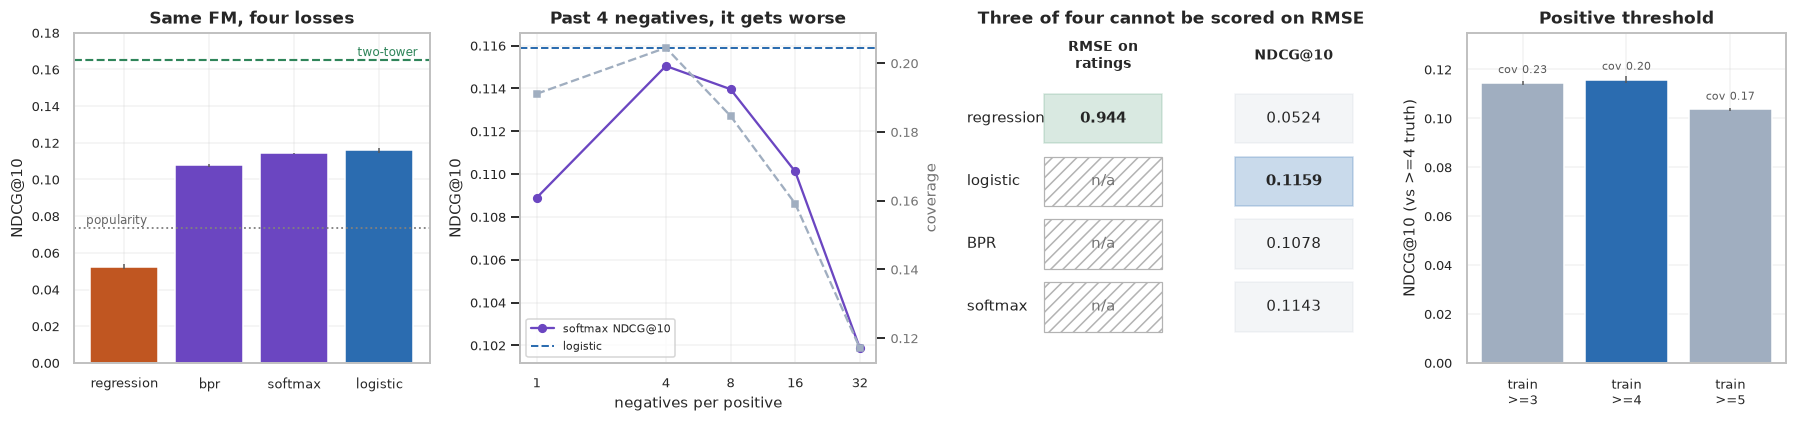

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16.5, 4.0), gridspec_kw={"width_ratios": [1, 1, 1.15, 0.9]})

# (a) objectives
ax = axes[0]
order = ["regression", "bpr", "softmax", "logistic"]
cols = [WARN, PURPLE, PURPLE, ACCENT]
ax.bar(range(4), [A8.loc[o, "ndcg"] for o in order], yerr=[A8.loc[o, "se"] for o in order],
       color=cols, edgecolor="white", error_kw=dict(ecolor="0.35", lw=1))
ax.axhline(TOWER, color=GOOD, ls="--", lw=1.4)
ax.text(3.45, TOWER + 0.002, "two-tower", color=GOOD, fontsize=8, ha="right")
ax.axhline(0.0737, color="0.5", ls=":", lw=1.2)
ax.text(-0.45, 0.0737 + 0.002, "popularity", color="0.4", fontsize=8)
ax.set_xticks(range(4)); ax.set_xticklabels(order, fontsize=8.5)
ax.set_ylabel("NDCG@10"); ax.set_ylim(0, 0.18)
ax.set_title("Same FM, four losses")

# (b) negative sweep
ax = axes[1]
ax.plot(SW["n_neg"], SW[f"ndcg@{K}"], "-o", ms=5, color=PURPLE, label="softmax NDCG@10")
ax.axhline(FM_LOGISTIC, color=ACCENT, ls="--", lw=1.3, label="logistic")
ax.set_xscale("log", base=2); ax.set_xticks([1, 4, 8, 16, 32]); ax.set_xticklabels([1, 4, 8, 16, 32])
ax.set_xlabel("negatives per positive"); ax.set_ylabel("NDCG@10")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(SW["n_neg"], SW["coverage"], "--s", ms=4, color=MUTED, label="coverage")
ax2.set_ylabel("coverage", color="0.45"); ax2.tick_params(axis="y", labelcolor="0.45")
ax.legend(fontsize=7.5, loc="lower left")
ax.set_title("Past 4 negatives, it gets worse")

# (c) the table with holes
ax = axes[2]; ax.axis("off")
rows_ = ["regression", "logistic", "BPR", "softmax"]
keys = ["regression", "logistic", "bpr", "softmax"]
ax.text(0.30, 0.93, "RMSE on\nratings", ha="center", va="center", fontsize=9, weight="bold")
ax.text(0.72, 0.93, "NDCG@10", ha="center", va="center", fontsize=9, weight="bold")
best_ndcg = A8["ndcg"].max()
for j, (lab, k) in enumerate(zip(rows_, keys)):
    y = 0.74 - j * 0.19
    ax.text(0.0, y, lab, ha="left", va="center", fontsize=9.5)
    if k == "regression":
        ax.add_patch(plt.Rectangle((0.17, y - 0.075), 0.26, 0.15, color=GOOD, alpha=0.18))
        ax.text(0.30, y, f"{A8.loc[k, 'rmse']:.3f}", ha="center", va="center", fontsize=10, weight="bold")
    else:
        ax.add_patch(plt.Rectangle((0.17, y - 0.075), 0.26, 0.15, facecolor="none",
                                   edgecolor="0.7", hatch="///", lw=0.8))
        ax.text(0.30, y, "n/a", ha="center", va="center", fontsize=9.5, color="0.45")
    v = A8.loc[k, "ndcg"]
    ax.add_patch(plt.Rectangle((0.59, y - 0.075), 0.26, 0.15,
                               color=ACCENT if v == best_ndcg else MUTED,
                               alpha=0.25 if v == best_ndcg else 0.12))
    ax.text(0.72, y, f"{v:.4f}", ha="center", va="center", fontsize=10,
            weight="bold" if v == best_ndcg else "normal")
ax.set_xlim(0, 0.9); ax.set_ylim(0, 1)
ax.set_title("Three of four cannot be scored on RMSE")

# (d) threshold
ax = axes[3]
x = np.arange(3)
ax.bar(x, TH["ndcg"], yerr=TH["se"], color=[MUTED, ACCENT, MUTED], edgecolor="white",
       error_kw=dict(ecolor="0.35", lw=1))
for xi, (t, r) in zip(x, TH.iterrows()):
    ax.text(xi, r["ndcg"] + 0.004, f"cov {r['cov']:.2f}", ha="center", fontsize=7.5, color="0.35")
ax.set_xticks(x); ax.set_xticklabels([f"train\n>={t}" for t in TH.index], fontsize=8.5)
ax.set_ylabel("NDCG@10 (vs >=4 truth)"); ax.set_ylim(0, 0.135)
ax.set_title("Positive threshold")

plt.tight_layout(); plt.show()

---
## 4. Findings

### The objective does not explain the two-tower's advantage

| FM objective | NDCG@10 | tower gap closed |
|---|---|---|
| logistic (pointwise) | 0.1159 ± 0.0015 | — |
| softmax, 8 negatives (listwise) | 0.1143 ± 0.0001 | none |
| BPR (pairwise) | 0.1078 ± 0.0008 | none |
| regression on ratings | 0.0524 ± 0.0015 | — |
| *two-tower (Phase 6)* | *0.1653* | |

Softmax and logistic are indistinguishable on the FM, and neither moves it toward the tower.
Pushing the softmax from 1 to 32 negatives does not help: quality peaks at 4 negatives
(0.1150) and then falls, while catalogue coverage collapses from 0.204 to 0.117.

Phase 6 showed negative *count* explains about 10% of the tower's lead; this phase shows the
*loss* explains none of it. What remains distinguishes the architectures rather than their
training: the tower has a nonlinear MLP inside each side, compares **L2-normalised**
embeddings through a temperature with no per-item bias term, and its towers carry genre, year
and demographic inputs the FM's best configuration dropped. Those are eliminated as a group,
not separated from each other — a clean single-factor test would be the tower with its MLPs
removed.

A plausible reason the FM degrades with more negatives, stated as a hypothesis rather than a
result: uniformly sampled negatives are overwhelmingly unpopular items, and the FM has a free
bias per item that can learn "popular beats unpopular" directly. More negatives reward that
shortcut, which is consistent with the coverage collapse. The tower's normalised dot product has
no such bias, and held 0.45 coverage with 256 negatives.

### Listwise losses are fragile to false negatives

Grouped objectives must draw negatives by the same rule as everything else — never an item the
user interacted with. An unfiltered uniform draw makes **9.4%** of negatives items the user
actually rated (59.6% for the heaviest user), and that alone lowers the FM softmax from 0.1143
to 0.0987 (**−14%**) and BPR from 0.1078 to 0.0982. Pointwise logistic never used such a
sampler. The asymmetry has a mechanism: a softmax concentrates its gradient on the
highest-scoring negatives, which is exactly where a real positive mislabelled as a negative
sits. The rule is enforced by a protocol test.

### The table with holes

| Objective | RMSE on ratings | NDCG@10 |
|---|---|---|
| regression | **0.944** | 0.0524 |
| logistic | n/a | **0.1159** |
| BPR | n/a | 0.1078 |
| softmax | n/a | 0.1143 |

Only regression produces a number on the rating scale. Logistic outputs a probability; BPR and
softmax output an *order* with no scale — raw scores above 40 — and their losses are unchanged
by adding a constant to every score, so no absolute prediction exists to be scored.

**The best model on RMSE is the worst ranker.** Regression beats the mean-rating baseline by
18% (0.944 vs 1.157), so it genuinely learned the rating scale — and it ranks below raw
popularity. It can only be trained where a rating exists, on items users *chose* to watch, then
must rank the catalogue they did not choose. That is Phase 1's selection bias, now visible as a
55% ranking deficit.

The study's own prediction was half right: regression did win RMSE, but the expected ranking
winner, BPR, came last of the three ranking-capable objectives.

### The positive threshold

Trained at `≥3`, `≥4` and `≥5` and evaluated against the same `≥4` truth: `≥3` and `≥4` are
indistinguishable on NDCG (0.1145 vs 0.1159), with `≥3` reaching further into the catalogue
(coverage 0.231 vs 0.204); `≥5` is clearly worse at 0.1036 (−10.6%). Phase 1 chose `≥4` for
class balance, a reason that stops applying once negatives are sampled — balance is 50% by
construction. The choice survives the test but is not uniquely right: calling a 3 a positive
costs nothing and broadens what gets recommended, while discarding the 4s throws signal away.